Enter image path:  image2.jpg


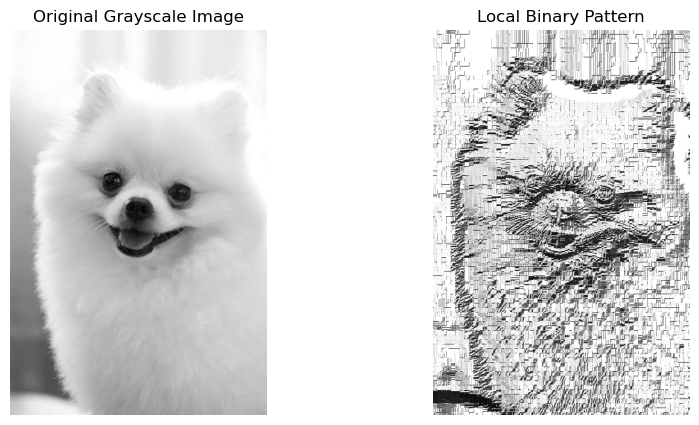

In [1]:
#Q1 Write a program to implement the local binary pattern on gray scale image.
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read input image in grayscale
path = input("Enter image path: ")
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")

else:
    # Create an empty LBP image
    lbp = np.zeros((img.shape[0]-2, img.shape[1]-2),
                   dtype=np.uint8)

    # Apply Local Binary Pattern
    for i in range(1, img.shape[0]-1):
        for j in range(1, img.shape[1]-1):

            center = img[i, j]

            neighbors = [
                img[i-1, j-1], img[i-1, j],
                img[i-1, j+1], img[i, j+1],
                img[i+1, j+1], img[i+1, j],
                img[i+1, j-1], img[i, j-1]
            ]

            binary = 0

            for k in range(8):
                if neighbors[k] >= center:
                    binary += 2 ** (7-k)

            lbp[i-1, j-1] = binary

    # Display original and LBP images
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Grayscale Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(lbp, cmap='gray')
    plt.title("Local Binary Pattern")
    plt.axis("off")

    plt.show()


Enter image path:  image2.jpg


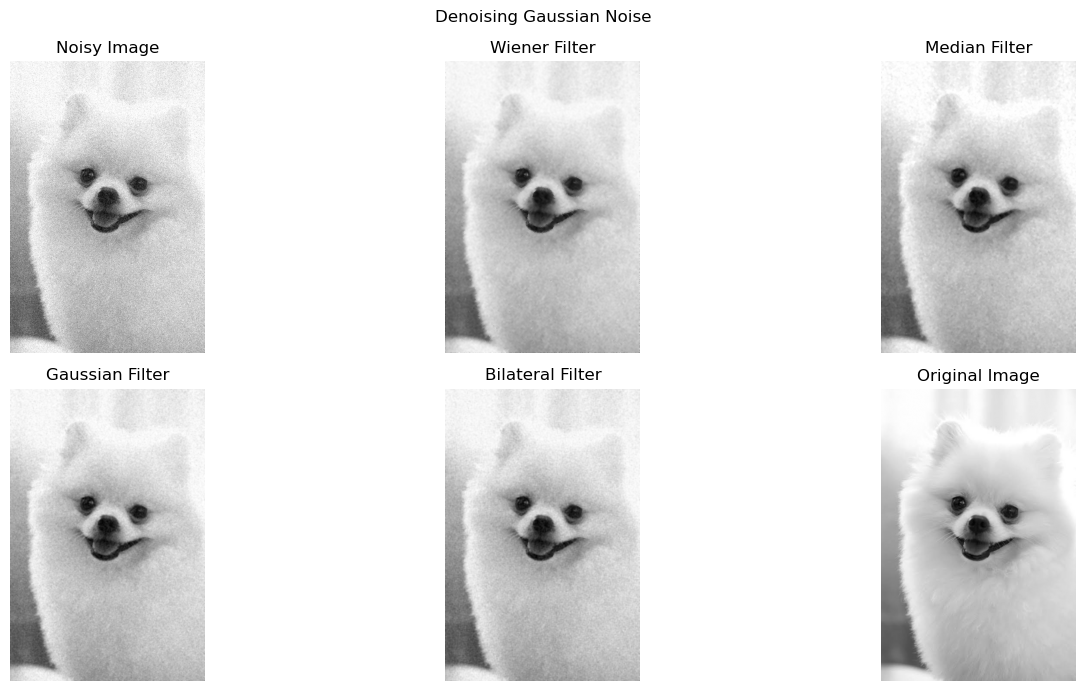

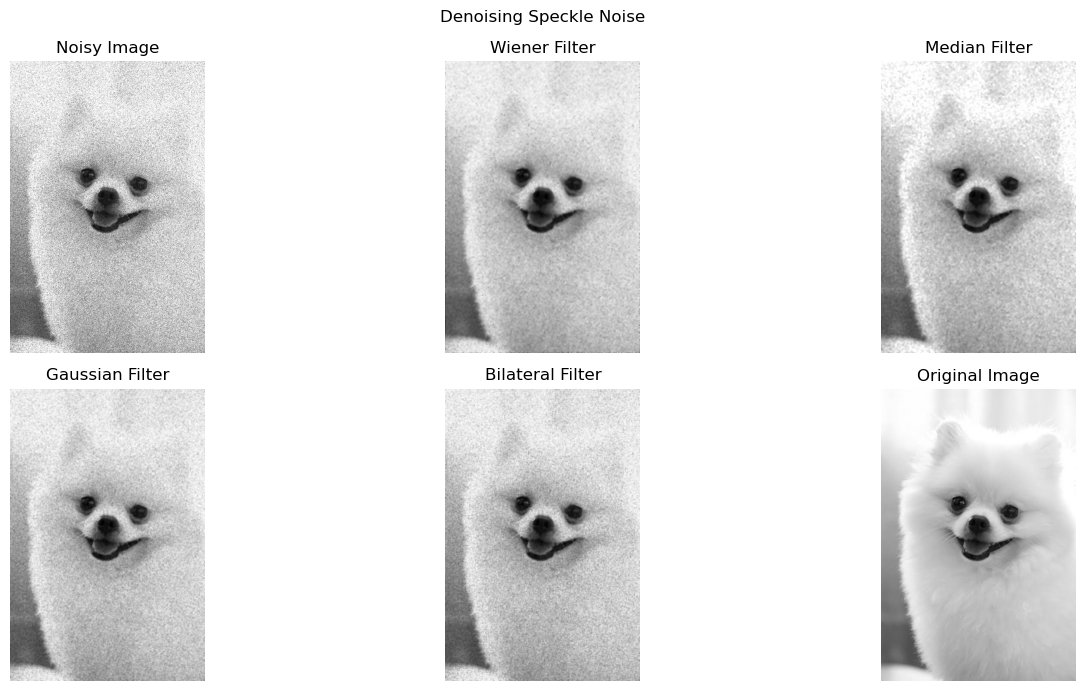

In [1]:
#Q2 Write a program to denoise the input image corrupted by Gaussian and Speckle noise by using following filters (3x3 or 5x5 window).  
                  
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

# Read input image in grayscale
path = input("Enter image path: ")
img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Image not found!")

else:
    # Convert image to float
    image = img.astype(np.float32)

    # Generate Gaussian noise
    gaussian_noise = np.random.normal(0, 20, img.shape)
    gaussian_img = np.clip(
        image + gaussian_noise, 0, 255
    ).astype(np.uint8)

    # Generate Speckle noise
    speckle_noise = np.random.normal(0, 0.2, img.shape)
    speckle_img = np.clip(
        image + image * speckle_noise, 0, 255
    ).astype(np.uint8)

    # Function to apply four filters
    def apply_filters(noisy_img):

        # Wiener filter
        wiener_img = wiener(
            noisy_img.astype(np.float32), (5, 5)
        )
        wiener_img = np.clip(
            wiener_img, 0, 255
        ).astype(np.uint8)

        # Median filter
        median_img = cv2.medianBlur(noisy_img, 5)

        # Gaussian filter
        gaussian_filtered = cv2.GaussianBlur(
            noisy_img, (5, 5), 0
        )

        # Bilateral filter
        bilateral_img = cv2.bilateralFilter(
            noisy_img, 5, 75, 75
        )

        return [
            noisy_img,
            wiener_img,
            median_img,
            gaussian_filtered,
            bilateral_img
        ]

    # Apply filters to both noisy images
    gaussian_results = apply_filters(gaussian_img)
    speckle_results = apply_filters(speckle_img)

    titles = [
        "Noisy Image",
        "Wiener Filter",
        "Median Filter",
        "Gaussian Filter",
        "Bilateral Filter"
    ]

    # Display Gaussian noise results
    plt.figure(figsize=(15, 7))
    for i in range(5):
        plt.subplot(2, 3, i + 1)
        plt.imshow(gaussian_results[i], cmap='gray')
        plt.title(titles[i])
        plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.suptitle("Denoising Gaussian Noise")
    plt.tight_layout()
    plt.show()

    # Display Speckle noise results
    plt.figure(figsize=(15, 7))
    for i in range(5):
        plt.subplot(2, 3, i + 1)
        plt.imshow(speckle_results[i], cmap='gray')
        plt.title(titles[i])
        plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")
    plt.axis("off")

    plt.suptitle("Denoising Speckle Noise")
    plt.tight_layout()
    plt.show()
